# Rabbits and foxes, by kinetic Monte Carlo

**CHME 5137, Lecture 10, Tuesday October 13, 2026.** Started in class, finished for
homework.

*Written for 2026 by Claude Code (Claude Opus 5.5) from Prof. West's KMC question of
earlier years, and checked by Prof. West. The problem is from Chapter 1 of H. Scott
Fogler's "Essentials of Chemical Reaction Engineering".*

---

Same farm, same rate constants: 400 rabbits and 200 foxes at the start, and

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

with $k_1 = 0.015$ day$^{-1}$, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$,
$k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$ and $k_4 = 0.04$ day$^{-1}$.

In the `solve_ivp` homework you found that the foxes fall to **under two** in each
trough. The ODEs don't mind: 1.6 foxes carry on and breed. Real foxes can't be
fractional, and two foxes can easily both die before they meet a rabbit. So now we
treat every rabbit and fox as an individual, and every birth and death as a random
event. That is **kinetic Monte Carlo** (KMC).

### The events

There are four events. Each has a rate, in events per day, which changes as the
populations change:

| Event | Rate | Effect |
|---|---|---|
| a rabbit is born | $k_1 R$ | $R \to R + 1$ |
| a rabbit is eaten | $k_2 R F$ | $R \to R - 1$ |
| a fox is born | $k_3 R F$ | $F \to F + 1$ |
| a fox dies | $k_4 F$ | $F \to F - 1$ |

The rates are easy to calculate, so we use the **rejection-free** algorithm, which you
worked out in class from
[Wikipedia's Kinetic Monte Carlo page](https://en.wikipedia.org/wiki/Kinetic_Monte_Carlo).
Writing it down in your own words is the first part of task 1.

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at. **Commit the `.ipynb`
  and its paired `.py` together**: the `.py` is the one whose diffs you can read on
  GitHub. If saving the notebook doesn't update the `.py`, see *Setting up Jupytext* on
  Canvas.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Random numbers:** use a NumPy generator, `rng = np.random.default_rng(seed)`,
  not the legacy `np.random.*` functions. Give it a seed, so that Restart & Run All
  gives the same answers every time. Check what interval each function returns,
  and what its arguments mean, before you trust it.
- **Let bugs shout.** If a population goes negative or an event isn't one of the
  four, `raise` an error. Don't hide it with `max(0, F)`: that turns a bug you'd
  notice into a wrong answer you won't.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

R0, F0 = 400, 200  # rabbits and foxes at t = 0
t_end = 600  # days

The deterministic answer, for comparison. This is the `solve_ivp` homework's
solution, at a tight tolerance.

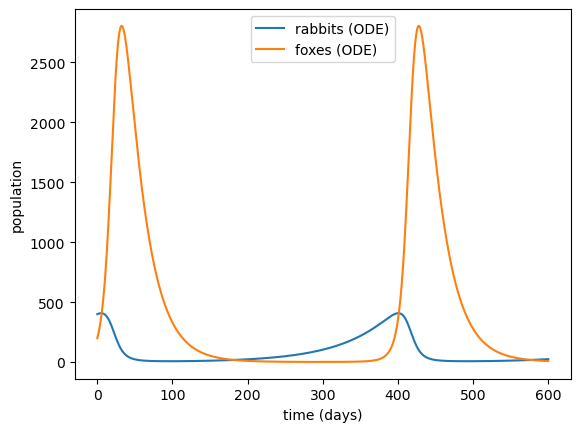

In [2]:
def dydt(t, y):
    R, F = y
    return [k1 * R - k2 * R * F, k3 * R * F - k4 * F]

ode = solve_ivp(dydt, (0, t_end), [R0, F0], rtol=1e-10, atol=1e-8, dense_output=True)
t_ode = np.linspace(0, t_end, 3001)
R_ode, F_ode = ode.sol(t_ode)

plt.plot(t_ode, R_ode, label="rabbits (ODE)")
plt.plot(t_ode, F_ode, label="foxes (ODE)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.legend()
plt.show()

## 1. One trajectory

**(a) The algorithm, in your own words.** Before you write any code, write the
rejection-free algorithm as numbered steps, for rabbits and foxes: what each of
Wikipedia's symbols ($k$, $r_{ki}$, $R_{ki}$, $Q_k$, $u$, $u'$) becomes here, how the
next event is chosen, and how far the clock moves. Then work the **first step by
hand**, from 400 rabbits and 200 foxes, with $u = 0.5$ and $u' = 0.3$: which event
happens, and how many minutes pass?

*Answer:*

**Wikipedia's symbols, for rabbits and foxes**

| Symbol | Here |
|---|---|
| $k$ | the current state, i.e. the numbers of rabbits and foxes $(R, F)$ |
| $r_{ki}$ | the rate of event $i$ in that state: $r_1 = k_1 R$, $r_2 = k_2 R F$, $r_3 = k_3 R F$, $r_4 = k_4 F$ (events/day) |
| $R_{ki}$ | the cumulative rate $R_{ki} = \sum_{j \le i} r_{kj}$, so $R_{k4} = Q_k$ |
| $Q_k$ | the total rate of all four events, $Q_k = r_1 + r_2 + r_3 + r_4$ |
| $u$ | a uniform random number in $(0, 1]$, used to **choose which event** happens |
| $u'$ | a second, independent uniform random number in $(0, 1]$, used to **choose how long** it takes |

**The algorithm**

1. Set $t = 0$, $R = 400$, $F = 200$.
2. Calculate the four rates $r_1 \ldots r_4$ from the current $R$ and $F$.
3. Form the cumulative rates $R_{k1}, R_{k2}, R_{k3}, R_{k4} = Q_k$. If $Q_k = 0$,
   nothing can happen, so stop.
4. Draw $u$ and pick the event $i$ with $R_{k,i-1} < u Q_k \le R_{ki}$. Each event is
   chosen with probability $r_{ki} / Q_k$.
5. Carry out that event: $R \pm 1$ or $F \pm 1$.
6. Draw $u'$ and move the clock on by $\Delta t = -\ln(u') / Q_k$. This is an exponentially
   distributed waiting time with mean $1/Q_k$.
7. Record $(t, R, F)$, and go back to step 2 until $t$ passes $t_\text{end}$.

**The first step by hand** ($R = 400$, $F = 200$, $u = 0.5$, $u' = 0.3$)

| $i$ | event | $r_i$ (1/day) | $R_{ki}$ (1/day) |
|---|---|---|---|
| 1 | rabbit born | $0.015 \times 400 = 6$ | 6 |
| 2 | rabbit eaten | $0.00004 \times 400 \times 200 = 3.2$ | 9.2 |
| 3 | fox born | $0.0004 \times 400 \times 200 = 32$ | 41.2 |
| 4 | fox dies | $0.04 \times 200 = 8$ | 49.2 |

$Q = 49.2$ events/day, and $uQ = 0.5 \times 49.2 = 24.6$. This falls between
$R_{k2} = 9.2$ and $R_{k3} = 41.2$, so **a fox is born**: $R = 400$, $F = 201$.

$$\Delta t = \frac{-\ln(0.3)}{49.2} = \frac{1.204}{49.2} = 0.02447 \text{ days}
= 0.02447 \times 1440 \approx \mathbf{35.2 \text{ minutes}}$$

**(b) The function.** Write

```python
def kmc(R0, F0, t_end, rng):
    ...
    return times, rabbits, foxes   # three NumPy arrays, one entry per event
```

that runs your algorithm from $t = 0$ until the clock passes `t_end`. If the total
rate is ever zero, nothing more can happen, so stop there.

Run it once. How many events were there, and how long did it take? Plot rabbits and
foxes against time, on top of the ODE solution. (`plt.step(times, foxes, where="post")`
draws a population that jumps, rather than one that slopes.) Run it a few more times
with different seeds. How does a KMC trajectory differ from the ODE solution?

24813 events in 0.09 s
at t = 602.4 days: 24 rabbits, 1 foxes


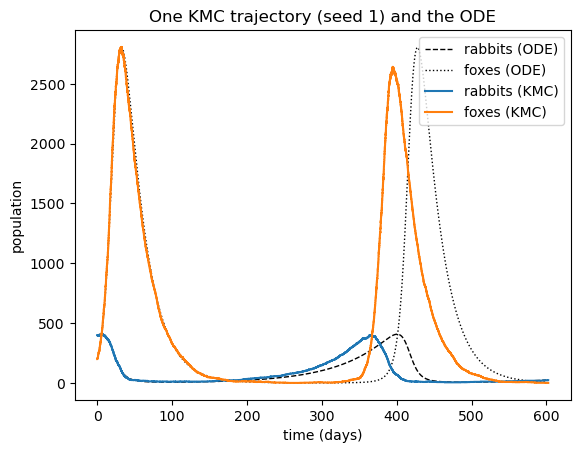

In [3]:
def kmc(R0, F0, t_end, rng):
    """One rejection-free KMC trajectory, from t = 0 until the clock passes t_end.

    Returns times, rabbits, foxes: NumPy arrays with one entry for the start and
    one per event.
    """
    R, F, t = R0, F0, 0.0
    times, rabbits, foxes = [t], [R], [F]
    while t < t_end:
        rates = np.array([k1 * R, k2 * R * F, k3 * R * F, k4 * F])  # r_ki, events/day
        cumulative = np.cumsum(rates)  # R_ki
        Q = cumulative[-1]  # Q_k
        if Q == 0:
            break  # no rabbits and no foxes, so nothing can ever happen again

        # rng.random() is in [0, 1). 1 - rng.random() is in (0, 1], so u > 0 never picks
        # an event with zero rate, and log(u_prime) is always finite.
        u = 1.0 - rng.random()
        u_prime = 1.0 - rng.random()

        i = np.searchsorted(cumulative, u * Q)  # first i with R_ki >= u Q
        if i == 0:
            R += 1  # a rabbit is born
        elif i == 1:
            R -= 1  # a rabbit is eaten
        elif i == 2:
            F += 1  # a fox is born
        elif i == 3:
            F -= 1  # a fox dies
        else:
            raise RuntimeError(f"event index {i} is not one of the four events")
        if R < 0 or F < 0:
            raise RuntimeError(f"negative population at t = {t}: R = {R}, F = {F}")

        t += -np.log(u_prime) / Q
        times.append(t)
        rabbits.append(R)
        foxes.append(F)
    return np.array(times), np.array(rabbits), np.array(foxes)


rng = np.random.default_rng(1)
start = time.perf_counter()
times, rabbits, foxes = kmc(R0, F0, t_end, rng)
elapsed = time.perf_counter() - start
print(f"{len(times) - 1} events in {elapsed:.2f} s")
print(f"at t = {times[-1]:.1f} days: {rabbits[-1]} rabbits, {foxes[-1]} foxes")

plt.plot(t_ode, R_ode, "k--", lw=1, label="rabbits (ODE)")
plt.plot(t_ode, F_ode, "k:", lw=1, label="foxes (ODE)")
plt.step(times, rabbits, where="post", label="rabbits (KMC)")
plt.step(times, foxes, where="post", label="foxes (KMC)")
plt.xlabel("time (days)")
plt.ylabel("population")
plt.title("One KMC trajectory (seed 1) and the ODE")
plt.legend()
plt.show()

The same thing with four other seeds, with the populations on a log scale so the
troughs show up.

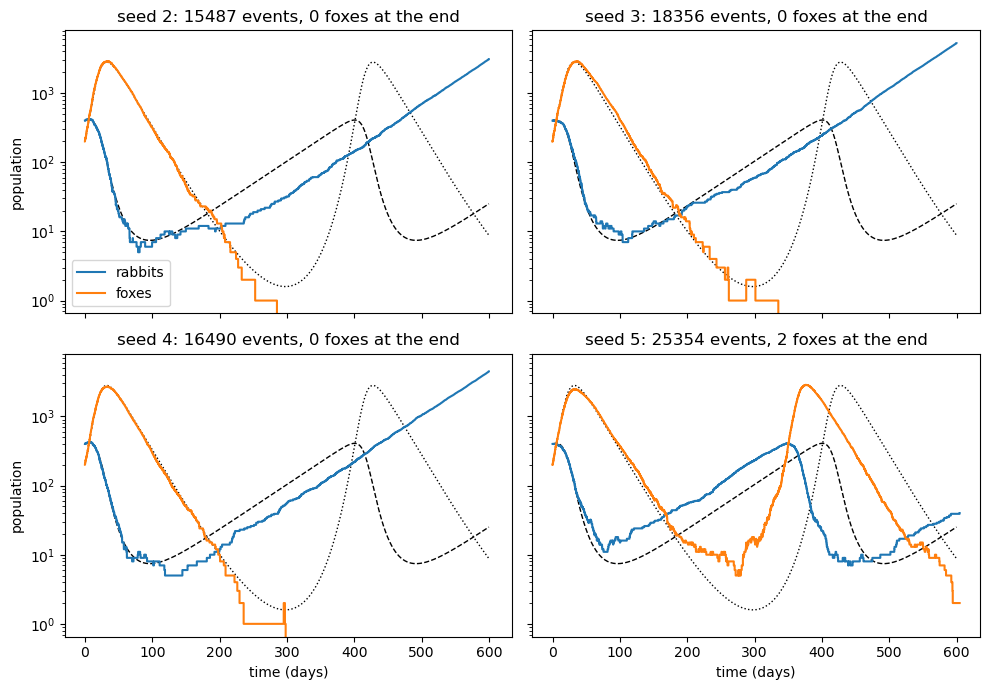

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for seed, ax in zip([2, 3, 4, 5], axes.flat):
    times, rabbits, foxes = kmc(R0, F0, t_end, np.random.default_rng(seed))
    ax.plot(t_ode, R_ode, "k--", lw=1)
    ax.plot(t_ode, F_ode, "k:", lw=1)
    ax.step(times, rabbits, where="post", label="rabbits")
    ax.step(times, foxes, where="post", label="foxes")
    ax.set_yscale("log")
    ax.set_title(f"seed {seed}: {len(times) - 1} events, {foxes[-1]} foxes at the end")
axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel("time (days)")
for ax in axes[:, 0]:
    ax.set_ylabel("population")
plt.tight_layout()
plt.show()

*Answer:*

With seed 1 there were **24,813 events**, which took about **0.1 s**. The clock
finished at day 602.4, just past `t_end`, with 24 rabbits and 1 fox left. Runs where
the foxes die out have fewer events (about 15,000–18,000), because there is no second
fox boom.

How a KMC trajectory differs from the ODE:

- **The populations are whole numbers that jump**, and they jitter around the ODE
  curve instead of following it smoothly. While populations are in the thousands
  (the first fox peak, around day 32) the jitter is relatively small and every run
  follows the ODE closely. The relative noise grows like $1/\sqrt{N}$, so it matters
  most in the troughs.
- **The foxes can die out.** The ODE's foxes go down to 1.6 at day 298 and come back.
  In seeds 2, 3 and 4 the KMC foxes reach zero between days 240 and 300 and never come
  back. The rabbits then grow exponentially at rate $k_1$ (a straight line on the log
  plot), to thousands by day 600, with no second cycle.
- **Even when the foxes survive, the timing drifts.** Seed 1 got down to a single
  fox at day 255 and survived by luck. Seed 5 bottomed out at 5 foxes. In both, the
  rabbits recovered a little ahead of the ODE, so the second fox peak came around day
  375–395, well before the ODE's day 428, and it was lower. Small random
  differences in the trough turn into large differences in the phase of the next
  cycle.

## 2. Many trajectories, and where they end up

Plot the foxes from 20 trajectories on one graph (thin lines, `lw=0.5`), with the ODE
solution on top.

- What do the trajectories have in common, and where do they spread apart?
- What happens to a trajectory once the foxes reach zero? Once the rabbits reach
  zero? Why can't it ever recover?
- Where in the cycle do the foxes usually die out, and why there? (Your answer to
  task 5 of the `solve_ivp` homework is relevant.)

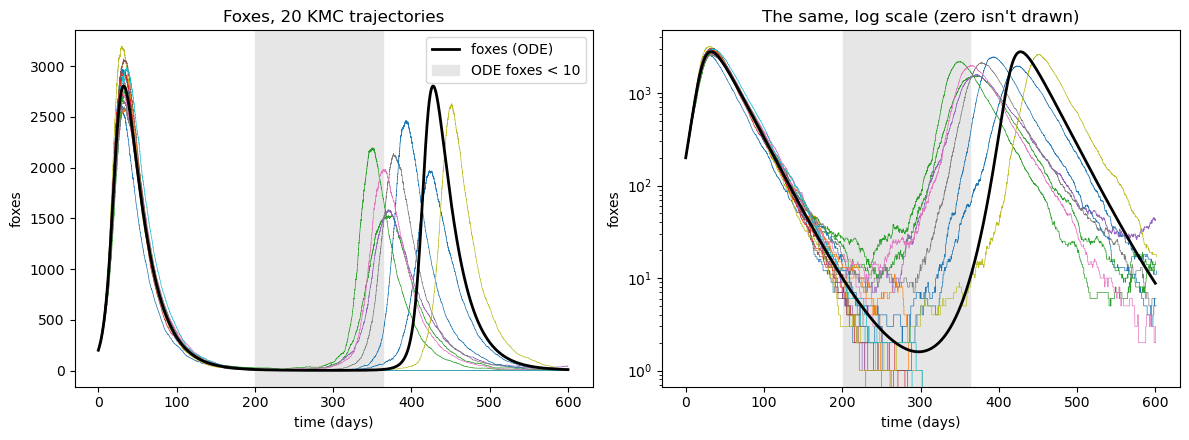

ODE fox trough: 1.59 foxes at day 298
ODE rabbits = k4/k3 = 100 at day 298

run  foxes die out at  rabbits then  rabbits at the end
  0  survive (12 foxes at day 600)          69
  1  day 302.0          168          15224
  2  survive (14 foxes at day 600)          106
  3  day 271.1           67          11485
  4  survive (42 foxes at day 600)          139
  5  day 265.4           51          6797
  6  day 261.2           53          11157
  7  survive (6 foxes at day 600)          100
  8  day 261.1           47          7577
  9  day 289.2           62          6300
 10  survive (5 foxes at day 600)          52
 11  day 263.1           47          6823
 12  survive (15 foxes at day 600)          157
 13  day 280.1           62          7351
 14  day 230.0           46          11538
 15  day 283.2           49          6296
 16  survive (3 foxes at day 600)          139
 17  day 250.0           55          10526
 18  survive (17 foxes at day 600)          14
 19  day 302.6         

In [5]:
rng = np.random.default_rng(2026)
trajectories = [kmc(R0, F0, t_end, rng) for _ in range(20)]

fig, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(12, 4.5))
for ax in (ax_lin, ax_log):
    for times, rabbits, foxes in trajectories:
        ax.step(times, foxes, where="post", lw=0.5)
    ax.plot(t_ode, F_ode, "k", lw=2, label="foxes (ODE)")
    ax.axvspan(*t_ode[(F_ode < 10) & (t_ode < 400)][[0, -1]], color="0.9", zorder=0,
               label="ODE foxes < 10")
    ax.set_xlabel("time (days)")
    ax.set_ylabel("foxes")
ax_log.set_yscale("log")
ax_lin.set_title("Foxes, 20 KMC trajectories")
ax_log.set_title("The same, log scale (zero isn't drawn)")
ax_lin.legend()
plt.tight_layout()
plt.show()

print(f"ODE fox trough: {F_ode[t_ode < 400].min():.2f} foxes "
      f"at day {t_ode[t_ode < 400][F_ode[t_ode < 400].argmin()]:.0f}")
print(f"ODE rabbits = k4/k3 = {k4 / k3:.0f} at day "
      f"{t_ode[(t_ode > 200) & (R_ode > k4 / k3)][0]:.0f}")
print("\nrun  foxes die out at  rabbits then  rabbits at the end")
for n, (times, rabbits, foxes) in enumerate(trajectories):
    if (rabbits == 0).any():
        raise RuntimeError(f"run {n}: the rabbits died out; handle this case")
    if foxes[-1] == 0:
        i = np.argmax(foxes == 0)
        print(f"{n:3d}  day {times[i]:5.1f}         {rabbits[i]:4d}          {rabbits[-1]}")
    else:
        print(f"{n:3d}  survive ({foxes[-1]} foxes at day {t_end})          {rabbits[-1]}")
n_extinct = sum(foxes[-1] == 0 for _, _, foxes in trajectories)
print(f"\nfoxes died out in {n_extinct} of {len(trajectories)} runs")

*Answer:*

**What they have in common, and where they spread apart.** All 20 trajectories
follow the ODE closely through the first fox peak, about 2,600–3,200 foxes at around
day 32, and down the decline to about day 150. Fox numbers are in the hundreds or
thousands there, so one birth or death hardly matters and the law of large numbers
makes the KMC behave like the ODE. They spread apart in the **trough** (the grey band,
where the ODE has fewer than 10 foxes). There each event is a sizeable fraction of
the population. Some runs go to zero, and the rest come out of the trough at
different times, so their second peaks are spread from about day 345 to 450 and from
about 1,500 to 2,600 foxes. Most come earlier and lower than the ODE's peak at day 428.

**Once the foxes reach zero**, the fox-birth rate $k_3 R F$ is zero, because new foxes
can only come from existing foxes. So $F$ stays at 0 forever. The only event left is
rabbit birth, so the rabbits grow exponentially as $e^{k_1 t}$, to thousands by day
600. **If the rabbits reached zero**, rabbit births ($k_1 R$) and fox births
($k_3 R F$) would both stop. The only event left would be fox deaths at $k_4 F$, so the
foxes would starve to extinction and the farm would end empty at $Q = 0$. That's
where the `Q == 0` stop in `kmc` comes in. (It didn't happen in these 20 runs.
The rabbits' lowest point, about 7 in the ODE, comes around day 490, so it is only
possible in runs that get to the second cycle.) Zero is an **absorbing state** for
each species. Every event that could create an animal has a rate proportional to the
number of that animal, so nothing can bring a species back from zero. The ODE never
reaches zero: there $F$ decays like $e^{-\text{rate}\, t}$, and 1.6 foxes can still breed.

**Where in the cycle the foxes die out.** In 12 of the 20 runs the foxes died out,
all between **day 230 and day 303**. That is the falling side of the trough, just
before the ODE's minimum of 1.6 foxes at day 298. The reason is the per-fox balance
of births and deaths. A fox is born at rate $k_3 R$ per fox and dies at rate $k_4$, so
the foxes shrink on average whenever $R < k_4 / k_3 = 100$ rabbits. In the ODE the
rabbits only climb back past 100 at about day 298, exactly where the fox curve turns
around (task 5 of the `solve_ivp` homework). Until then, each fox is more likely to die
than to breed: at day 230 there are about 37 rabbits, so births are only 37% as likely
as deaths. The foxes are down to a handful at exactly the time when every one is more
likely to die than to reproduce, which is the most dangerous combination. The rabbits
when the last fox died were mostly 45–70, below 100. In run 19 the rabbits lagged
behind (still about 20 at day 300), so its dangerous stretch lasted longer. Run 1 had
168 rabbits but was down to its last fox, which can die before it breeds even when the
odds favour breeding. Once $R > 100$ the foxes grow on average, and the runs that made
it that far went on to a second peak.

## 3. The second fox peak

The ODE's foxes peak at about day 32, and again at about day 428, at about 2804
foxes each time. When is the second peak in a KMC trajectory, and how high?

A noisy trajectory has lots of tiny local maxima, so we need a definition. Use this
one: **the largest number of foxes after day 200, counted as a peak only if it is
above 100 foxes and isn't within 5 days of either end of the window** (day 200 or
day 600). Write a function `second_peak(times, foxes)` that returns `(time, height)`,
or `None` if there isn't one.

Run 100 trajectories. In what fraction is there a second peak? For those that have
one, give the mean and median of its time and of its height, and the interquartile
range (25th to 75th percentile, `np.percentile`) of each. Plot histograms.

How do these compare with the ODE's second peak? If they differ, why? And what does
the definition get wrong? Find a trajectory where it picks something you wouldn't
call "the second peak", if you can.

*Answer:*

## 4. How many runs are enough?

Every number in task 3 came from random runs, so it has its own uncertainty. Repeat
task 3 with 100, 300, 1000 and 3000 trajectories. (Time it first, and work out how
long 3000 will take before you start.)

- How do the mean second-peak time and height change with the number of runs?
- Work out the **standard error** of each mean, $s / \sqrt{n}$, where $s$ is the
  standard deviation and $n$ the number of trajectories with a peak. How does it
  scale with $n$?
- Give the expected time and height of the second peak, and their interquartile
  ranges, to a precision you can justify. Say how you justified it.

*Answer:*

## 5. How likely is it that the foxes die out?

From your largest set of runs, what fraction have **no foxes left at day 600**?
That fraction $p$ estimates a probability. Its standard error is
$\sqrt{p(1-p)/N}$ for $N$ runs.

- Give the probability that the foxes die out before 600 days, with its uncertainty.
- How many runs would you need to know it to within ±1 percentage point? To within
  ±0.1?
- Plot a histogram of the times at which the foxes die out. When does it usually
  happen?

*Answer:*

## 6. Your project

One paragraph. Is there any part of your project where the numbers are small
enough, or the events discrete and random enough, that a continuum model (an ODE or
a PDE) could mislead you, the way the ODE does about the foxes? Think about
molecules on a surface, cells, bubbles, particles, defects, failures. If there is,
what would the "events" and their rates be? If there isn't, why is a continuum model
good enough?

*Answer:*

## Stretch problems

**(a) Faster.** Time one trajectory. Then find where the time goes (`%prun`, or
time the pieces). Try Python's `random.random()` in place of `rng.random()`,
appending to lists versus filling a preallocated array, and recording only every
100th event. How much faster can you make it?

**(b) Bigger, on Explorer.** The `.py` paired with this notebook is a script.
Make a copy that runs 10,000 trajectories and saves the second-peak times and heights
and the extinction times with `np.savetxt`, and run it as a batch job on Explorer,
as in Lecture 9. Do your answers to tasks 4 and 5 hold up?

**(c) Is the random clock worth it?** Wikipedia notes that advancing the clock by
$\Delta t = 1/Q_k$ every step, instead of an exponentially distributed $\Delta t$, gives
"the same *average* time scale" (and that note is marked *citation needed*). Test it.
Make a copy of your `kmc` function that uses $\Delta t = 1/Q$, and run both versions
many times. Compare the probability that the foxes die out by day 600, the fraction of
runs with a second peak, and the mean time and height of that peak, each with its
standard error. Which differences are bigger than their uncertainty? How many runs did
you need before you could tell? (Several thousand of each; (a) and (b) help.) Why might
some quantities change and others not?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.